>Implementar una función que calcule las componentes principales de un conjunto de datos a partir de su descomposici ́on en valores singulares (SVD). Para el calculo de las matrices de valores singulares pueden usar las bibliotecas y módulos ya conocidos

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from numpy import ndarray

df = pd.read_csv('./europe.csv', delimiter=',')
df.head()

,Country,Area,GDP,Inflation,Life.expect,Military,Pop.growth,Unemployment
0,Austria,83871,41600,3.5,79.91,0.80,0.03,4.2
1,Belgium,30528,37800,3.5,79.65,1.30,0.06,7.2
2,Bulgaria,110879,13800,4.2,73.84,2.60,-0.80,9.6
3,Croatia,56594,18000,2.3,75.99,2.39,-0.09,17.7
4,Czech Republic,78867,27100,1.9,77.38,1.15,-0.13,8.5


Voy a escalar el dataframe por comodidad. Podría no hacerlo y ver qué pasa

In [3]:
id = 'Country'
features = list(set(df.columns) - {id})
X = df[features].to_numpy()
std_scale = StandardScaler()
std_scale.fit(X)
X_scaled = std_scale.transform(X)

algoritmo PCA:
* centrar X
* Hacer SVD
* Calcular varianza por componente  y varianza total
* Calcular proporción de varianza explicada por componente
* Truncar matrices
* Proyectar X centrado sobre matrices calculadas
* Devolver $X_{proyectado}$ en $q$ componentes, $V_q^t$ (matriz de $q$ componentes principales), array con cantidad de varianza explicada por componente

In [4]:
def pca_svd(X:ndarray, n_componentes:int|None=None):
    X_bar = np.mean(X, axis=0)
    X_centrado = X - X_bar
    N = X.shape[0]
    
    #obs: d es un array
    U, d, Vt = np.linalg.svd(X_centrado, full_matrices=False)

    #varianza explicada
    sigma_cuad = (d ** 2) / (N - 1)
    var_total = np.sum(sigma_cuad)
    varianza_explicada_ratio = sigma_cuad / var_total

    if n_componentes is None:
        n_componentes = X.shape[1]
    #truncar a las primeras q dimensiones
    U_q = U[:, :n_componentes]
    D_q = np.diag(d[:n_componentes])
    Vt_q = Vt[:n_componentes, :]
    
    #calcular los lambda_ij = U_q * D_q
    X_proyectado = np.dot(U_q, D_q)  
    #se podría calcular de la misma forma X_proyectado = X_centrado @ Vt_q.T

    return X_proyectado, Vt_q, varianza_explicada_ratio[:n_componentes]

X_proyectado, componentes, varianza_explicada = pca_svd(X_scaled)

Grafiquitos ↓

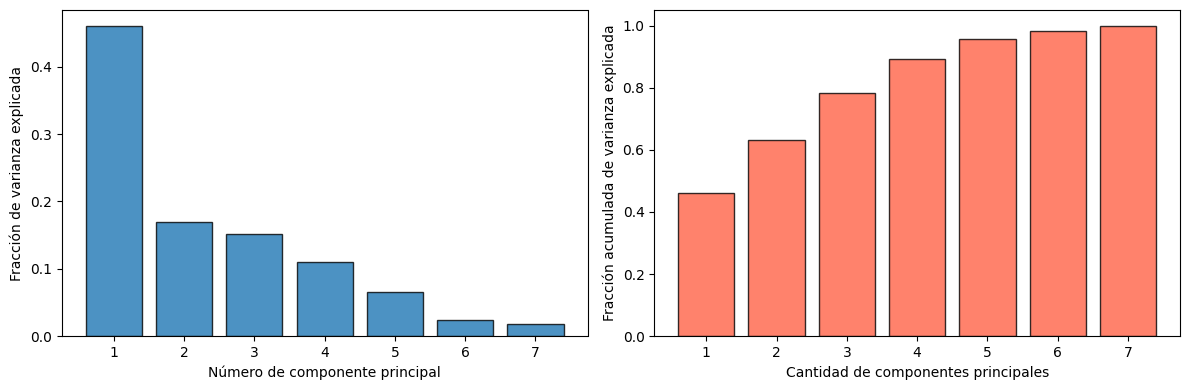

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Eje X común (número de componentes)
n_componentes = range(1, len(varianza_explicada) + 1)

# 1. Gráfico de varianza explicada individual
ax[0].bar(n_componentes, varianza_explicada, edgecolor='black', alpha=0.8)
ax[0].set_ylabel('Fracción de varianza explicada')
ax[0].set_xlabel('Número de componente principal')
ax[0].set_xticks(n_componentes) # Para asegurar que muestre cada número entero

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# 2. Gráfico de varianza acumulada
ax[1].bar(n_componentes, varianza_acumulada, color = 'tomato',edgecolor='black', alpha=0.8)
ax[1].set_ylabel('Fracción acumulada de varianza explicada')
ax[1].set_xlabel('Cantidad de componentes principales')
ax[1].set_xticks(n_componentes)

plt.tight_layout()
plt.show()

Composición de las componentes en función de las features originales

In [12]:
componentes_df = pd.DataFrame(
    [[round(float(a), 3) for a in componentes[i]] for i in range(len(componentes))],
    columns=features,
    index=[f'Comp. Principal {i}'for i in range(1, len(componentes) + 1)]
)
componentes_df

,Military,GDP,Life.expect,Unemployment,Inflation,Area,Pop.growth
Comp. Principal 1,0.188,-0.501,-0.483,0.272,0.407,0.125,-0.476
Comp. Principal 2,0.658,-0.130,0.265,0.553,-0.370,-0.173,0.083
Comp. Principal 3,0.244,0.084,0.246,0.001,0.198,0.898,0.164
Comp. Principal 4,0.562,0.084,-0.027,-0.702,-0.165,-0.045,-0.392
Comp. Principal 5,0.368,0.391,-0.102,0.010,0.690,-0.324,0.348
Comp. Principal 6,-0.036,-0.639,0.606,-0.260,0.324,-0.190,0.121
Comp. Principal 7,-0.137,0.397,0.507,0.245,0.227,-0.067,-0.671


Proyeccion de features en el espacio de componentes principales

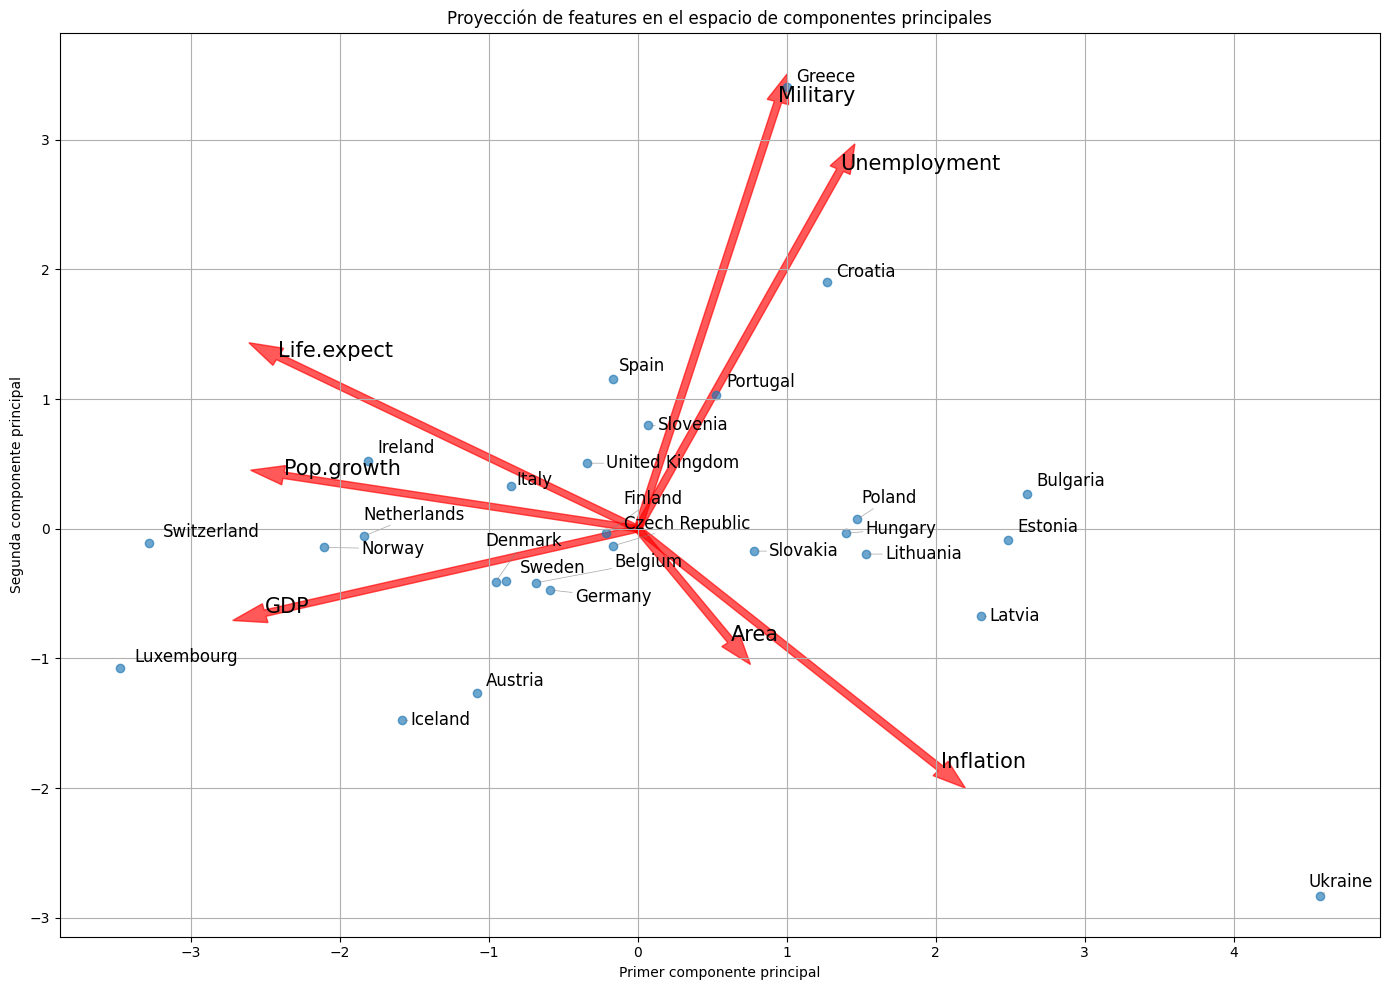

In [7]:
from adjustText import adjust_text
fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de features en el espacio de componentes principales')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes[0][i], escala * componentes[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes[0][i], escala * componentes[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado[i, 0], X_proyectado[i, 1], pais, fontsize=12)
    texts.append(t)

ax.scatter(X_proyectado[:, 0], X_proyectado[:, 1], alpha=0.65)


adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()

Repito análisis con la implementación de sklearn

In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=None)
pca.fit(X_scaled)
X_proyectado_sklearn = pca.transform(X_scaled)
varianza_explicada_sklearn = pca.explained_variance_ratio_
componentes_sklearn = pca.components_

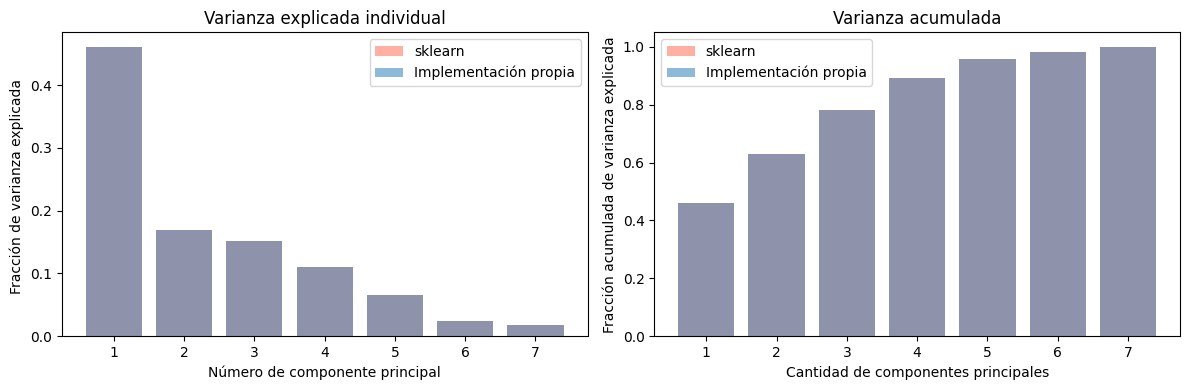

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Eje X común (número de componentes)
n_componentes = range(1, len(varianza_explicada_sklearn) + 1)

# 1. Gráfico de varianza explicada individual
ax[0].bar(n_componentes, varianza_explicada_sklearn,color = 'tomato', alpha=0.5, label='sklearn')
ax[0].bar(n_componentes, varianza_explicada, alpha=0.5, label='Implementación propia')
ax[0].set_ylabel('Fracción de varianza explicada ')
ax[0].set_xlabel('Número de componente principal')
ax[0].set_xticks(n_componentes) # Para asegurar que muestre cada número entero
ax[0].set_title('Varianza explicada individual')
ax[0].legend()
# Varianza acumulada
varianza_acumulada_sklearn = np.cumsum(varianza_explicada_sklearn)

# 2. Gráfico de varianza acumulada
ax[1].bar(n_componentes, varianza_acumulada_sklearn, color = 'tomato', alpha=0.5, label='sklearn')
ax[1].bar(n_componentes, varianza_acumulada, alpha=0.5, label='Implementación propia')
ax[1].legend()
ax[1].set_ylabel('Fracción acumulada de varianza explicada')
ax[1].set_xlabel('Cantidad de componentes principales')
ax[1].set_xticks(n_componentes)
ax[1].set_title('Varianza acumulada')
plt.tight_layout()
plt.show()

In [13]:

componentes_df_sklearn = pd.DataFrame(
    [[round(float(a), 3) for a in componentes_sklearn[i]] for i in range(len(componentes_sklearn))],
     
    columns=features,
    index=[f'Comp. Principal {i}' for i in range(1, len(componentes_sklearn) + 1)]
)
print('Comparación de componentes principales')
print('-----------------------------------')
for i, row in componentes_df.iterrows():
    print(f'{i}:\n{componentes_df_sklearn.loc[i].values} (sklearn) \n{componentes_df.loc[i].values} (implementación propia)\n')


Comparación de componentes principales
-----------------------------------
Comp. Principal 1:
[-0.188  0.501  0.483 -0.272 -0.407 -0.125  0.476] (sklearn) 
[ 0.188 -0.501 -0.483  0.272  0.407  0.125 -0.476] (implementación propia)

Comp. Principal 2:
[ 0.658 -0.13   0.265  0.553 -0.37  -0.173  0.083] (sklearn) 
[ 0.658 -0.13   0.265  0.553 -0.37  -0.173  0.083] (implementación propia)

Comp. Principal 3:
[0.244 0.084 0.246 0.001 0.198 0.898 0.164] (sklearn) 
[0.244 0.084 0.246 0.001 0.198 0.898 0.164] (implementación propia)

Comp. Principal 4:
[-0.562 -0.084  0.027  0.702  0.165  0.045  0.392] (sklearn) 
[ 0.562  0.084 -0.027 -0.702 -0.165 -0.045 -0.392] (implementación propia)

Comp. Principal 5:
[ 0.368  0.391 -0.102  0.01   0.69  -0.324  0.348] (sklearn) 
[ 0.368  0.391 -0.102  0.01   0.69  -0.324  0.348] (implementación propia)

Comp. Principal 6:
[ 0.036  0.639 -0.606  0.26  -0.324  0.19  -0.121] (sklearn) 
[-0.036 -0.639  0.606 -0.26   0.324 -0.19   0.121] (implementación propia

SKLearn invierte el sentido de las componentes 1, 4, 6 y 7 respecto de las de la implementación propia. Esto se puede observar en la inversión horizontal del gráfico siguiente


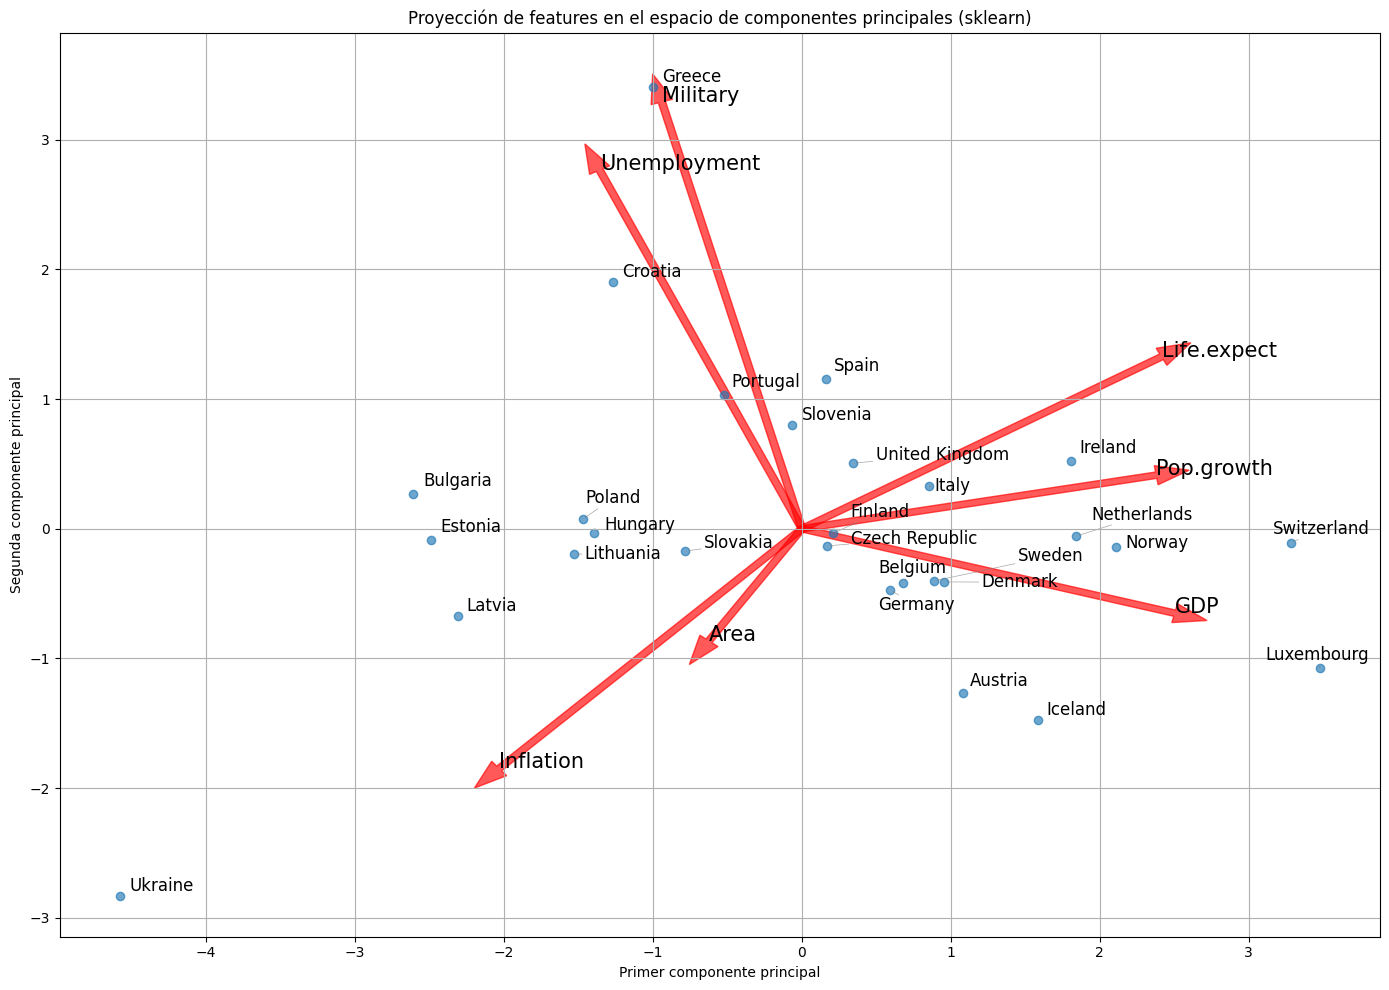

In [11]:
fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de features en el espacio de componentes principales (sklearn)')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes_sklearn[0][i], escala * componentes_sklearn[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes_sklearn[0][i], escala * componentes_sklearn[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado_sklearn[i, 0], X_proyectado_sklearn[i, 1], pais, fontsize=12)
    texts.append(t)

ax.scatter(X_proyectado_sklearn[:, 0], X_proyectado_sklearn[:, 1], alpha=0.65)


adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()

Agregamos cuatro filas de datos al conjunto original: Argentina del 2012, del 2024, Brasil del 2012 y del 2024. Las iremos introduciendo de a una al análisis para observar cómo cada nuevo dato cambia los resultados.

El primer dato agregado corresponde a Argentina del 2012, año que se corresponde con las mediciones de los datos originales

In [17]:
df_expandido = pd.read_csv('./dataset_expandido.csv', delimiter=',')
df_expandido.tail()

X_expandido = df_expandido[features].to_numpy()
std_scaler_2 = StandardScaler()
std_scaler_2.fit(X_expandido)
X_scaled_expandido = std_scaler_2.transform(X_expandido)
X_proyectado_expandido, componentes_expandido, varianza_explicada_expandido = pca_svd(X_scaled_expandido)

Proyección de las features en el espacio de componentes


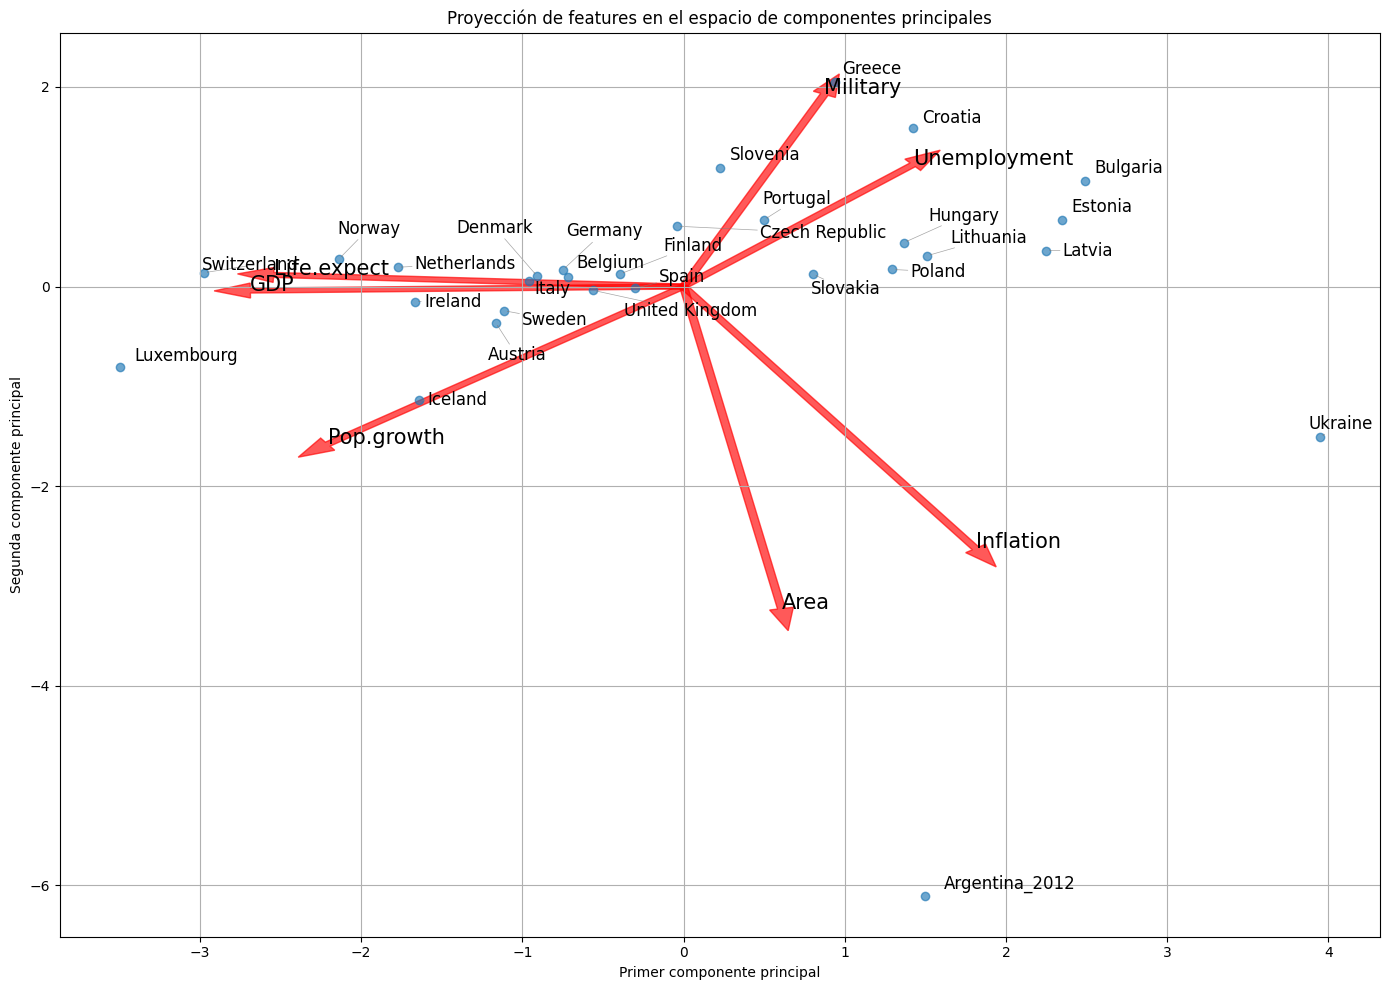

In [18]:

fig, ax = plt.subplots(figsize=(14, 10))
ax.grid(True)
ax.set_title('Proyección de features en el espacio de componentes principales')
texts = []

escala = 5
for i in range(len(features)):
    ax.arrow(0, 0, escala * componentes_expandido[0][i], escala * componentes_expandido[1][i], 
             width=0.05, color='r', alpha=0.65)
    ax.text(escala * componentes_expandido[0][i], escala * componentes_expandido[1][i], 
            s=features[i], fontdict={'color': 'k', 'size': 15})
for i, row in df_expandido.iterrows():
    pais = row[id]
    t = ax.text(X_proyectado_expandido[i, 0], X_proyectado_expandido[i, 1], pais, fontsize=12)
    texts.append(t)

ax.scatter(X_proyectado_expandido[:, 0], X_proyectado_expandido[:, 1], alpha=0.65)


adjust_text(texts, ax=ax, 
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.5, alpha=0.7))

ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()